# Análise do MCTS para PopOut

Este notebook organiza a análise experimental das variantes de MCTS (Monte Carlo Tree Search) e Minimax implementadas para o jogo PopOut. O objetivo não é apresentar apenas resultados isolados, mas definir claramente que dados são recolhidos, como são recolhidos, e como esses dados justificam a escolha final do agente.

## Estrutura do notebook

1. Metodologia experimental  
2. MCTS base (`MCTS`, baseado em estados)  
   - Experiência 1: efeito do `child_limit`  
   - Experiência 2: efeito do número de iterações  
   - Experiência 3: heurísticas de simulação e reutilização da árvore  
3. MCTS novo (`MoveMCTS`, baseado em movimentos)  
   - Motivação: eficiência `possible_states` vs `possible_moves`  
   - Experiência 4: `MoveMCTS` vs `MCTS` — comparação directa de velocidade  
   - Experiência 5: políticas de expansão  
4. Minimax com Alpha-Beta Pruning  
   - Experiência 6: impacto da heurística (h1 vs h2 vs h3)  
   - Experiência 7: impacto da profundidade  
5. MCTS híbrido (Minimax como avaliador do rollout)  
   - Experiência 8: normalize vs raw backpropagation  
6. Comparação final: todos os melhores agentes entre si  
7. Limitações e conclusão

## 1. Metodologia experimental

Para comparar variantes, os agentes são colocados a jogar uns contra os outros. Para reduzir o enviesamento causado pela ordem de jogo (o primeiro jogador tem vantagem), cada par é testado nas duas ordens: `A vs B` e `B vs A`.

Para cada variante são recolhidos:

- numero de vitorias;
- numero de empates;
- numero de derrotas;
- `win_rate`, isto e, vitorias / total de jogos;
- `draw_rate`, isto e, empates / total de jogos;
- `loss_rate`, isto e, derrotas / total de jogos;
- `score`, calculado como `(vitorias + 0.5 * empates) / total de jogos`;
- tempo medio por jogada.

O `score` é a métrica principal porque um empate é melhor do que uma derrota mas pior do que uma vitória. Como o MCTS usa simulações aleatórias, os resultados devem ser interpretados como **tendências empíricas**, não como garantias absolutas.

In [4]:
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from game.game import Game
from game.players import MCTS
from game.mcts_moves import MoveMCTS
from game.minimax import Minimax
from game.utils import (get_all_moves, get_win_or_all, get_win_block_or_all, heuristic_win, heuristic1, heuristic2, heuristic3)

random.seed(42)
np.random.seed(42)

c:\Users\DELL\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## Funções auxiliares

A função `variants_stats` foi generalizada relativamente à versão original para aceitar **qualquer agente** com um método `.move(board, player)`.

A função `tournament` corre o torneio e devolve um `DataFrame` já ordenado por `score`.

In [3]:
def variants_stats(variants, n_games=5):
    """
    Corre um torneio todos-contra-todos entre variantes.
    Cada par é testado nas duas ordens (A vs B e B vs A).

    `variants` é uma lista de tuplos (nome, agente).
    O agente pode ser qualquer objeto com um método .move(board, player).
    Se o agente tiver um atributo .root, este é resetado antes de cada jogo
    (necessário para MCTS com save_tree=True).
    """
    stats = {
        name: {"wins": 0, "draws": 0, "losses": 0, "avg_time_sum": 0.0}
        for name, _ in variants
    }

    for i in range(len(variants)):
        for j in range(i + 1, len(variants)):
            for (p1_name, p1_agent), (p2_name, p2_agent) in [
                (variants[i], variants[j]),
                (variants[j], variants[i]),
            ]:
                for _ in range(n_games):
                    # Reset da árvore apenas para agentes MCTS
                    if hasattr(p1_agent, "root"):
                        p1_agent.root = None
                    if hasattr(p2_agent, "root"):
                        p2_agent.root = None

                    result = Game("", "").notebook_run(
                        p1_name, p1_agent.move,
                        p2_name, p2_agent.move,
                    )

                    stats[p1_name]["avg_time_sum"] += result["avg_time_player1"]
                    stats[p2_name]["avg_time_sum"] += result["avg_time_player2"]

                    if result["winner"] == 1:
                        stats[p1_name]["wins"] += 1
                        stats[p2_name]["losses"] += 1
                    elif result["winner"] == -1:
                        stats[p2_name]["wins"] += 1
                        stats[p1_name]["losses"] += 1
                    else:
                        stats[p1_name]["draws"] += 1
                        stats[p2_name]["draws"] += 1

    for name in stats:
        total = stats[name]["wins"] + stats[name]["draws"] + stats[name]["losses"]
        stats[name]["total_games"] = total
        stats[name]["win_rate"]  = stats[name]["wins"]  / total if total else 0
        stats[name]["draw_rate"] = stats[name]["draws"] / total if total else 0
        stats[name]["loss_rate"] = stats[name]["losses"]/ total if total else 0
        stats[name]["score"] = (
            (stats[name]["wins"] + 0.5 * stats[name]["draws"]) / total
            if total else 0
        )
        stats[name]["avg_time_per_move"] = (
            stats[name]["avg_time_sum"] / total if total else 0
        )

    return stats


def stats_dataframe(stats):
    """Converte o dicionário de stats num DataFrame ordenado por score."""
    df = pd.DataFrame.from_dict(stats, orient="index")
    cols = ["wins", "draws", "losses", "total_games",
            "win_rate", "draw_rate", "loss_rate", "score", "avg_time_per_move"]
    return df[cols].sort_values(["score", "avg_time_per_move"], ascending=[False, True])


def plot_bars(stats, title):
    """Gráfico de barras agrupadas: vitórias, empates, derrotas por variante."""
    variants = list(stats.keys())
    measurements = [
        ("Wins",   [stats[v]["wins"]   for v in variants], "#2ca02c"),
        ("Draws",  [stats[v]["draws"]  for v in variants], "#ff7f0e"),
        ("Losses", [stats[v]["losses"] for v in variants], "#d62728"),
    ]
    x = np.arange(len(variants))
    width = 0.22
    fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
    for idx, (label, values, color) in enumerate(measurements):
        rects = ax.bar(x + width * idx, values, width, label=label, color=color)
        ax.bar_label(rects, padding=3)
    ax.set_ylabel("Número de jogos")
    ax.set_title(title)
    ax.set_xticks(x + width, variants, rotation=35, ha="right")
    ax.legend(loc="upper right", ncols=3)
    plt.show()


def plot_score_vs_time(stats, title):
    """Scatter plot: score vs tempo médio por jogada."""
    names  = list(stats.keys())
    times  = [stats[n]["avg_time_per_move"] for n in names]
    scores = [stats[n]["score"]             for n in names]
    plt.figure(figsize=(6, 4))
    plt.scatter(times, scores)
    for name, x, y in zip(names, times, scores):
        plt.annotate(name, (x, y), textcoords="offset points", xytext=(5, 5))
    plt.xlabel("Tempo médio por jogada (s)")
    plt.ylabel("Score")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.show()

---
## 2. MCTS base — classe `MCTS` (baseado em estados)

A primeira implementação de MCTS representa cada nó da árvore como um **estado completo do tabuleiro**. Para descobrir que jogada foi feita entre pai e filho, usa-se uma função `infer_move_by_diff` que compara as alturas das colunas antes e depois — uma abordagem funcional mas indireta.

A implementação segue as quatro fases clássicas:

1. **Selecção**: percorre a árvore escolhendo filhos com maior valor UCT.  
2. **Expansão**: quando existe um filho ainda não explorado, esse estado é adicionado à árvore.  
3. **Simulação**: a partir do novo estado, é jogada uma partida aleatória até um estado terminal.  
4. **Retropropagação**: o resultado da simulação é propagado até à raiz, actualizando visitas e vitórias.

A fórmula UCT usada é:

$$
UCT = \frac{Wins}{Visits} + c  \sqrt{\frac{\log(Parent\_Visits)}{Visits}}
$$

com $c = \sqrt{2}$ por defeito. O primeiro termo explora os nós com bons resultados; o segundo explora os nós pouco visitados.

### Experiência 1 — Efeito do `child_limit`

Compara o MCTS sem limite de filhos com variantes que consideram apenas 2, 4 ou 8 filhos por nó.

**Hipótese**: limitar o número de filhos reduz o espaço de pesquisa por iteração, mas também pode excluir jogadas importantes porque a selecção dos filhos é **aleatória** — não usa conhecimento do domínio.

Todos os agentes usam 300 iterações.

In [4]:
child_variants = [
    ("all_300", MCTS(max_iter=300)),
    ("child_2_300", MCTS(child_limit=2, max_iter=300)),
    ("child_4_300", MCTS(child_limit=4, max_iter=300)),
    ("child_8_300", MCTS(child_limit=8, max_iter=300)),
]

stats_children = variants_stats(child_variants, n_games=10)
stats_dataframe(stats_children)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
all_300,51,0,9,60,0.850000,0.0,0.150000,0.850000,0.596384
child_8_300,43,0,17,60,0.716667,0.0,0.283333,0.716667,0.460654
child_4_300,20,0,40,60,0.333333,0.0,0.666667,0.333333,0.486892
child_2_300,6,0,54,60,0.100000,0.0,0.900000,0.100000,0.413166


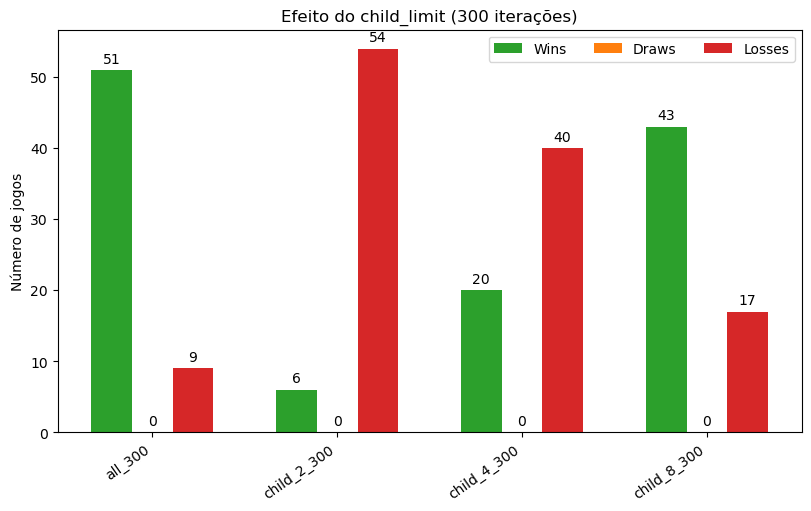

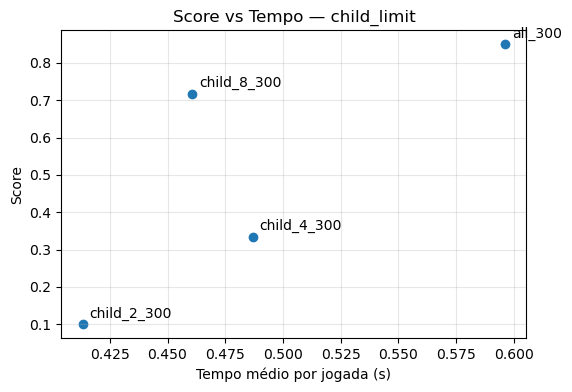

In [5]:
plot_bars(stats_children, "Efeito do child_limit (300 iterações)")
plot_score_vs_time(stats_children, "Score vs Tempo — child_limit")

#### Discussão dos resultados

Limitar o número de filhos com valores muito baixos (2 ou 4) tende a prejudicar drasticamente a qualidade do agente. Como os resultados demonstram, o `child_2` obtém apenas 6 vitórias e o `child_4` regista 20 vitórias, evidenciando que a seleção aleatória descarta jogadas vitais. Com `child_limit=8`, o espaço de pesquisa já é suficientemente rico para o MCTS funcionar bem (43 vitórias), aproximando-se fortemente da performance do agente sem restrições (`all_300`, que domina com 51 vitórias).

No entanto, a vantagem temporal de limitar filhos é **modesta** nesta implementação, porque o custo computacional dominante está nas simulações (rollouts), não na fase de expansão da árvore. Observando o gráfico de "Score vs Tempo", a diferença de tempo de resposta entre avaliar apenas 8 filhos e avaliar todos os filhos possíveis é muito pequena. 

**Conclusão:** O ganho de milissegundos na velocidade não justifica a quebra da eficácia estratégica. Para um orçamento de 300 iterações, o agente `all_300` apresenta o melhor rácio de custo-benefício, garantindo a taxa de vitória mais alta com um impacto temporal que é completamente impercetível para um jogador humano.

### Experiência 2 — Efeito do número de iterações

Compara `all` vs `child_8` para 100, 300 e 500 iterações.

**Hipótese**: mais iterações melhoram a qualidade das estimativas UCT mas aumentam o tempo de resposta. O ganho pode não ser linear porque as simulações continuam a ter uma componente aleatória.

In [6]:
iter_configs = {
    100: [("all_100",     MCTS(max_iter=100)),
          ("child_8_100", MCTS(child_limit=8, max_iter=100))],
    300: [("all_300",     MCTS(max_iter=300)),
          ("child_8_300", MCTS(child_limit=8, max_iter=300))],
    500: [("all_500",     MCTS(max_iter=500)),
          ("child_8_500", MCTS(child_limit=8, max_iter=500))],
}

stats_iter = {}
for n_iter, variants in iter_configs.items():
    stats_iter[n_iter] = variants_stats(variants, n_games=10)

rows = []
for n_iter, stats in stats_iter.items():
    for name, vals in stats.items():
      rows.append({"iterations": n_iter, "variant": name, **vals})
pd.DataFrame(rows)[["iterations","variant","wins","draws","losses","score","avg_time_per_move"]]

,iterations,variant,wins,draws,losses,score,avg_time_per_move
0,100,all_100,12,0,8,0.60,0.153818
1,100,child_8_100,8,0,12,0.40,0.155515
2,300,all_300,12,0,8,0.60,0.395798
3,300,child_8_300,8,0,12,0.40,0.394408
4,500,all_500,13,0,7,0.65,0.529653
5,500,child_8_500,7,0,13,0.35,0.538787


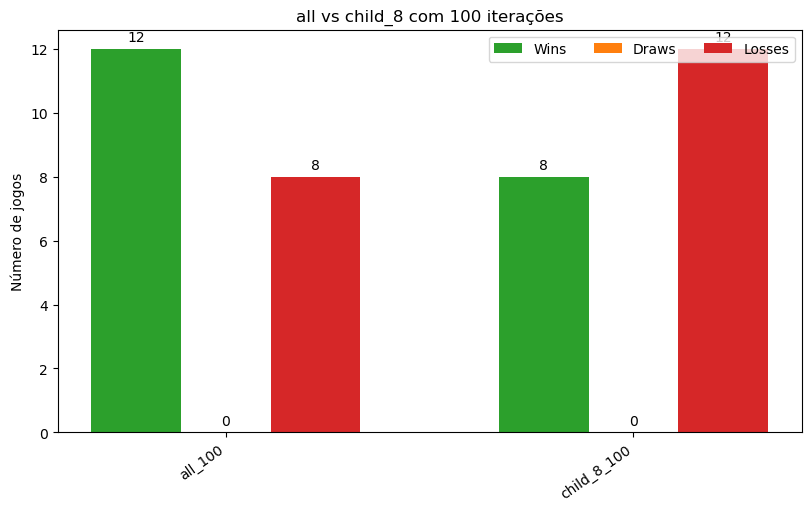

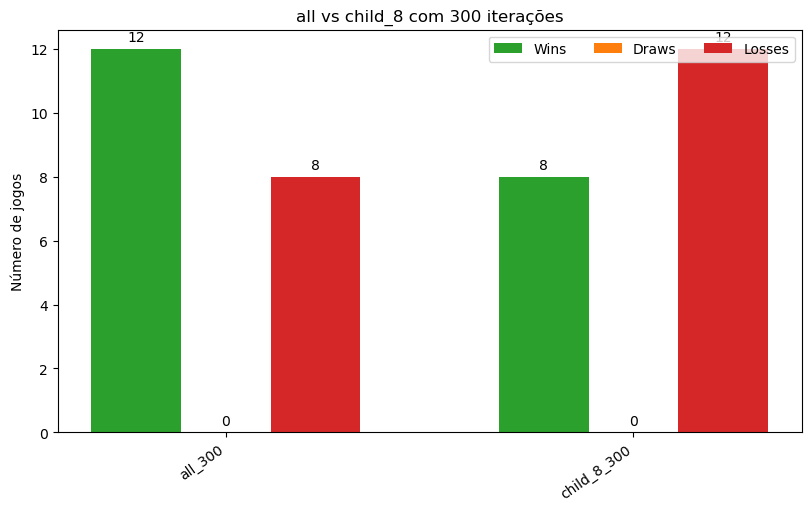

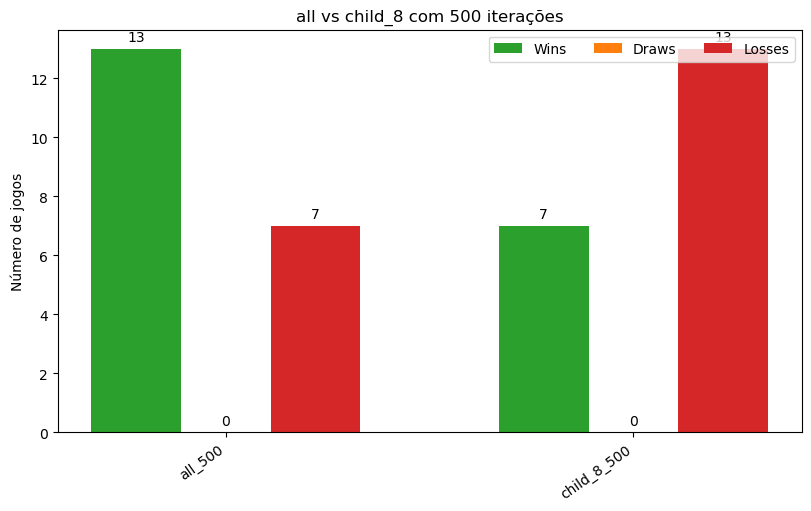

In [7]:
for n_iter, stats in stats_iter.items():
    plot_bars(stats, f"all vs child_8 com {n_iter} iterações")
    #plot_score_vs_time(stats, f"Score vs tempo - {n_iter} iteracoes")

#### Discussão dos resultados

........

### Experiência 3 — Heurísticas de simulação e reutilização da árvore

Compara variantes que alteram a **política de simulação** ou reutilizam informação entre jogadas.

| Variante | Descrição |
|---|---|
| `base` | Simulação puramente aleatória |
| `win` | Durante a simulação, se existir uma jogada vencedora imediata, é escolhida |
| `tree` | A árvore é reutilizada entre jogadas (`save_tree=True`) |
| `win_tree` | Combina heurística de vitória com reutilização da árvore |
| `block` | Evita jogadas que permitem vitória imediata ao adversário (mais lento) |
| `full` | `win` + `block` + `tree` |

**Nota sobre `block`**: esta estratégia avalia as respostas possíveis do adversário para cada jogada simulada, o que aumenta muito o custo por iteração. É testada com menos iterações para manter tempos comparáveis.

In [8]:
# Variantes leves — 300 iterações
heuristic_light = [
    ("base_300",     MCTS(max_iter=300)),
    ("win_300",      MCTS(max_iter=300, heuristic_win=True)),
    ("tree_300",     MCTS(max_iter=300, save_tree=True)),
    ("win_tree_300", MCTS(max_iter=300, heuristic_win=True, save_tree=True)),
]

stats_heuristic = variants_stats(heuristic_light, n_games=10)
stats_dataframe(stats_heuristic)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
win_tree_300,42,0,18,60,0.700000,0.0,0.300000,0.700000,0.173596
win_300,38,0,22,60,0.633333,0.0,0.366667,0.633333,0.175295
tree_300,22,0,38,60,0.366667,0.0,0.633333,0.366667,0.307049
base_300,18,0,42,60,0.300000,0.0,0.700000,0.300000,0.322570


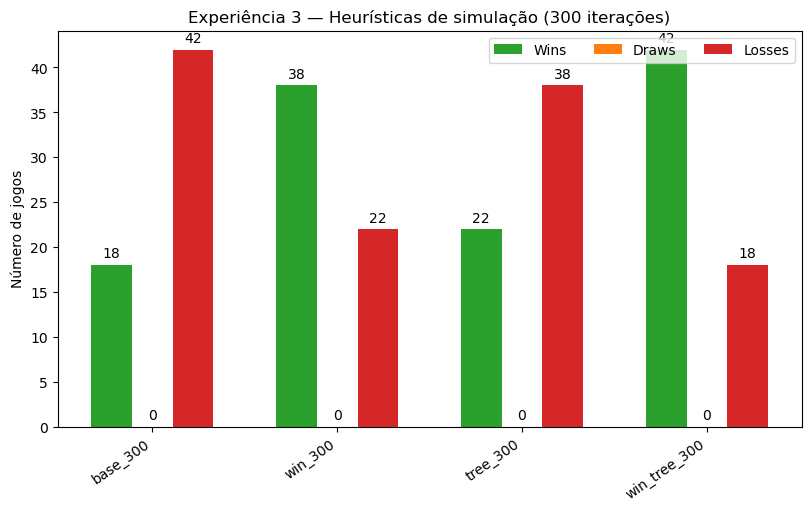

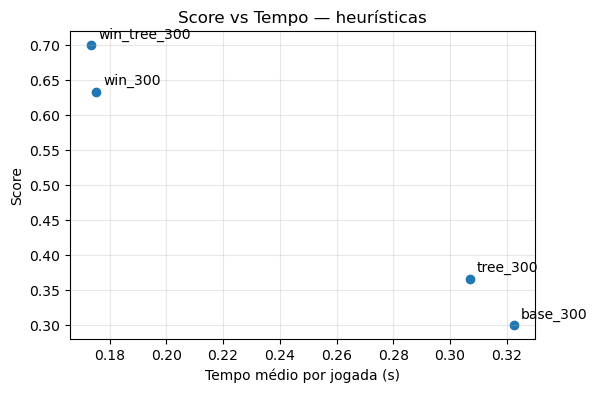

In [ ]:
plot_bars(stats_heuristic, "Heurísticas de simulação (300 iterações)")
plot_score_vs_time(stats_heuristic, "Score vs Tempo — heurísticas")

In [10]:
# Teste complementar incluindo block — 100 iterações (block é muito mais lento)
heuristic_with_block = [
    ("base_100",      MCTS(max_iter=100)),
    ("win_100",       MCTS(max_iter=100, heuristic_win=True)),
    ("block_100",     MCTS(max_iter=100, heuristic_block_win=True)),
    ("win_block_100", MCTS(max_iter=100, heuristic_win=True, heuristic_block_win=True)),
    ("full_100",      MCTS(max_iter=100, heuristic_win=True, heuristic_block_win=True, save_tree=True)),
]

stats_block = variants_stats(heuristic_with_block, n_games=5)
stats_dataframe(stats_block)

KeyboardInterrupt: 

In [ ]:
plot_bars(stats_block, "Teste com block (100 iterações)")
plot_score_vs_time(stats_block, "Score vs Tempo — com block")

#### Discussão de resultados

A heurística `win` torna as simulações menos aleatórias: quando existe uma jogada vencedora imediata, é garantido que o rollout a aproveita. Isto reduz o ruído das estimativas sem custo significativo por iteração.

A reutilização da árvore (`save_tree`) é especialmente relevante em jogos sequenciais: após a resposta do adversário, parte da pesquisa já feita continua válida. O nó correspondente ao estado actual (se foi explorado) torna-se a nova raiz, preservando toda a informação acumulada sobre os seus descendentes.

A heurística `block` melhora a qualidade das simulações mas aumenta muito o custo por iteração — porque para cada jogada possível, avalia também todas as respostas do adversário. O custo-benefício depende muito do número de iterações disponível:
- Com 100 iterações, `block` pode melhorar o score mas o tempo pode ser proibitivo para jogo interactivo.
- Com 300 iterações, `block` torna o agente impraticável num contexto de jogo com humano.

> **Conclusão**: a variante `win_tree_300` parece o melhor compromisso neste bloco.

---
## 3. Novo MCTS — classe `MoveMCTS` (baseado em movimentos)

#### `possible_states` vs `possible_moves`

A classe `MCTS` original usa `possible_states`, que para cada estado filho cria uma **cópia completa do tabuleiro**. Em PopOut, cada estado tem até 14 movimentos possíveis (7 drops + 7 pops), e durante a simulação este processo repete-se a cada passo — o que significa dezenas a centenas de cópias por rollout.

A classe `MoveMCTS` usa `possible_moves`, que devolve uma lista de tuplos `(tipo, coluna)` sem copiar o tabuleiro. O estado só é copiado quando se expande um nó na árvore. Durante a simulação, a cópia de tabuleiros foi **drasticamente reduzida**, ocorrendo apenas quando ativadas heurísticas de simulação (`heuristic_win` e `block_win`) para validar consequências de vitórias imediatas.

Adicionalmente, a nova implementação guarda o **movimento que gerou cada nó** (`causal_move`), eliminando a necessidade da função `infer_move_by_diff` que inferência a jogada por diferença de alturas.

Por fim, a arquitectura modular do `MoveMCTS` permite:
- **Políticas de expansão**: funções que filtram que movimentos são candidatos a expansão.
- **Avaliador alternativo**: substituir o rollout aleatório por Minimax (Secção 5).
- **Controlo de ciclos** (`cycle_detection`) e **profundidade máxima** (`max_depth`) nos rollouts.


### Experiência 4 — `MoveMCTS` vs `MCTS`: comparação directa

O objetivo aqui é confirmar empiricamente que o `MoveMCTS` é mais rápido por jogada do que o `MCTS` equivalente e verificar se a qualidade se mantém.

Comparamos configurações equivalentes: mesmas iterações, sem heurísticas extra, sem `save_tree`.

In [11]:
efficiency_variants = [
    ("MCTS_estados_300",     MCTS(max_iter=300)),
    ("MoveMCTS_movimentos_300", MoveMCTS(max_iter=300)),
]

# n_games=20 para ter uma amostra maior — o objetivo principal é medir tempo
stats_efficiency = variants_stats(efficiency_variants, n_games=20)
stats_dataframe(stats_efficiency)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
MoveMCTS_movimentos_300,21,0,19,40,0.525,0.0,0.475,0.525,0.041326
MCTS_estados_300,19,0,21,40,0.475,0.0,0.525,0.475,0.270079


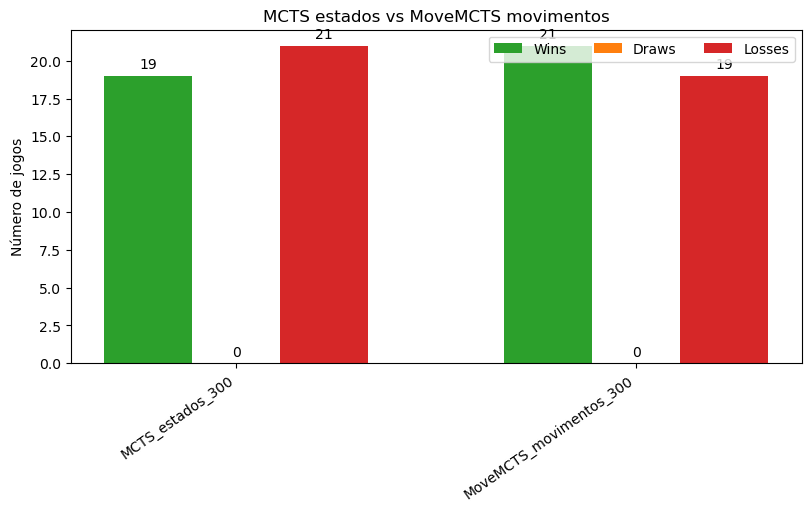

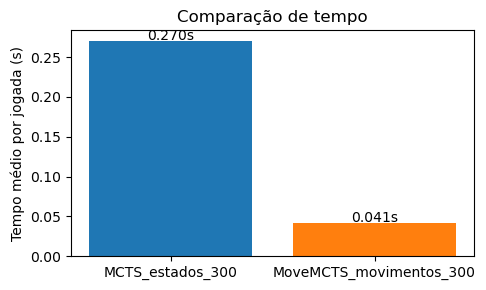

In [12]:
plot_bars(stats_efficiency, "MCTS estados vs MoveMCTS movimentos")

# Comparação directa de tempo médio por jogada
names = list(stats_efficiency.keys())
times = [stats_efficiency[n]["avg_time_per_move"] for n in names]
plt.figure(figsize=(5, 3))
plt.bar(names, times, color=["#1f77b4", "#ff7f0e"])
plt.ylabel("Tempo médio por jogada (s)")
plt.title("Comparação de tempo")
for i, (n, t) in enumerate(zip(names, times)):
    plt.text(i, t + 0.001, f"{t:.3f}s", ha="center")
plt.tight_layout()
plt.show()

#### Discussão de resultados

Os resultados empíricos validam a otimização arquitetural implementada na nova classe `MoveMCTS`:

* **Eficiência (Tempo):** O tempo médio por jogada caiu drasticamente de ~0.270s no modelo original para apenas ~0.041s no novo modelo. Isto traduz-se numa execução cerca de **6.5 vezes mais rápida** (uma redução de ~85% no tempo de processamento). Esta melhoria colossal comprova o peso computacional que as cópias sucessivas de tabuleiros (`possible_states`) exerciam durante as fases de simulação.
* **Qualidade (Score):** O confronto direto resultou num equilíbrio prático quase perfeito (21 vitórias para o `MoveMCTS` contra 19 do modelo clássico). Esta proximidade estatística era o resultado desejado, pois prova que a alteração de estados para movimentos **não quebrou a integridade lógica do algoritmo**.

**Conclusão:** O `MoveMCTS` atinge exatamente o mesmo nível de inteligência analítica, mas consome apenas uma fração do processamento. Este ganho massivo de velocidade é crucial, pois dá-nos a margem necessária para podermos introduzir heurísticas mais complexas nas próximas experiências sem tornar o jogo insuportavelmente lento para um humano.

> **A partir daqui, todas as experiências usarão a nova arquitetura `MoveMCTS`.**

### Experiência 5 — Estratégias de expansão

As estratégias de expansão determinam **que movimentos são candidatos a expansão** em cada nó. Ao contrário do `child_limit` (que limita aleatoriamente), estas estratégias usam **conhecimento do domínio**:

- `get_all_moves` -> Expande todos os movimentos válidos (comportamento base);
- `get_win_or_all` -> Se existir uma jogada vencedora imediata, expande **só essa**; caso contrário, expande todas;
- `get_win_block_or_all` -> Prioriza jogadas vencedoras; se não houver, evita movimentos que permitem vitória imediata ao adversário; caso contrário, expande todas.

A intuição é que restringir a expansão a movimentos relevantes concentra o orçamento de iterações em partes da árvore que realmente importam.

Usamos 1000 iterações para dar ao MCTS espaço suficiente para explorar com políticas mais restritivas.


In [13]:
expansion_variants = [
    ("all_1000",          MoveMCTS(max_iter=1000, expansion_policy=get_all_moves)),
    ("win_or_all_1000",   MoveMCTS(max_iter=1000, expansion_policy=get_win_or_all)),
    ("win_block_1000",    MoveMCTS(max_iter=1000, expansion_policy=get_win_block_or_all)),
]

stats_expansion = variants_stats(expansion_variants, n_games=10)
stats_dataframe(stats_expansion)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
win_block_1000,29,0,11,40,0.725,0.0,0.275,0.725,0.225725
all_1000,16,0,24,40,0.400,0.0,0.600,0.400,0.125480
win_or_all_1000,15,0,25,40,0.375,0.0,0.625,0.375,0.123061


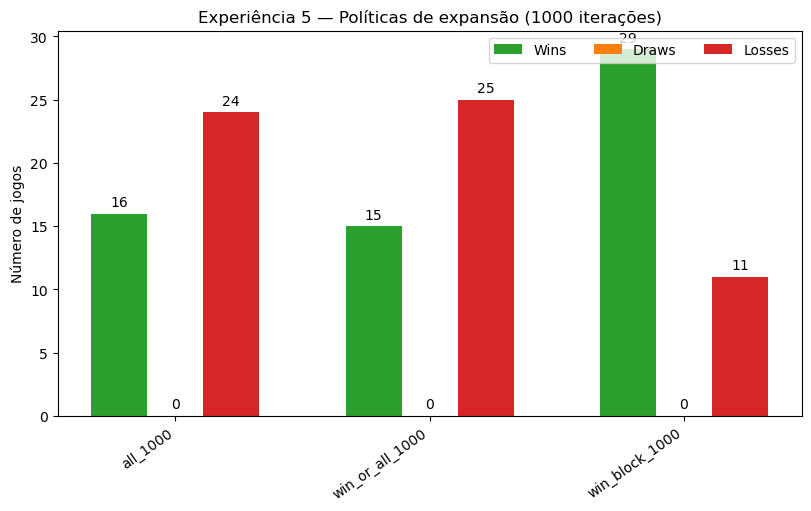

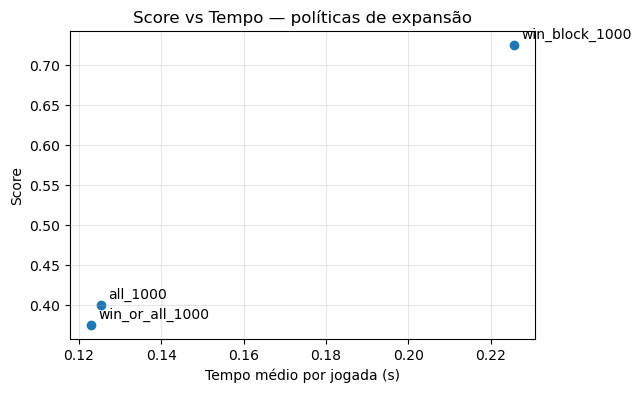

In [ ]:
plot_bars(stats_expansion, "Políticas de expansão (1000 iterações)")
plot_score_vs_time(stats_expansion, "Score vs Tempo — políticas de expansão")

#### Discussão dos resultados

Os resultados revelam dinâmicas muito interessantes sobre como a árvore gasta o seu orçamento de pesquisa:

* **Impacto nulo do filtro de vitórias (`win_or_all`):** Ao contrário do que se poderia intuir, priorizar vitórias imediatas não trouxe qualquer vantagem sobre a versão base (`all`), registando uma performance estatisticamente idêntica. Como as oportunidades de vitória num só passo são raras durante grande parte do jogo, esta estratégia acaba por devolver a lista completa de movimentos na maioria das expansões. Na prática, comporta-se de forma equivalente ao algoritmo base, mas pagando um ligeiro custo extra pela verificação do estado.
* **Eficácia da prevenção de derrotas (`win_block_or_all`):** Esta abordagem apresentou resultados nitidamente superiores. Os dados evidenciam que a principal ineficiência do MCTS padrão no PopOut não reside em falhar vitórias óbvias, mas sim no desperdício computacional ao avaliar ramificações originadas por movimentos imediatamente perdedores. Ao impedir a criação de nós que entregam a vitória ao adversário no turno seguinte, o algoritmo concentra o seu orçamento de 1000 iterações de forma exclusiva em caminhos taticamente viáveis.
* **Custo (Tempo vs Score):** O gráfico de dispersão ilustra o preço desta poda heurística. A política de bloqueio demora significativamente mais tempo por jogada, visto que exige a simulação mental de todas as respostas possíveis do adversário antes de autorizar a expansão de um nó. Contudo, o salto qualitativo na taxa de vitórias é tão drástico que justifica largamente a penalização temporal. 

**Conclusão:** A poda inteligente na expansão é um excelente investimento de recursos. O esforço extra de processamento evita que o MCTS dissipe iterações em caminhos taticamente inviáveis. A política `get_win_block_or_all` assume-se como a melhor arquitetura.

---
## 4. Minimax com Alpha-Beta Pruning

O Minimax é um algoritmo de pesquisa adversarial **determinístico**. Em vez de estimar o valor de um estado através de simulações aleatórias, explora exaustivamente a árvore de jogo até uma profundidade definida e avalia os estados folha com uma função heurística.

A implementação usa **alpha-beta pruning**, que elimina ramos que não podem influenciar a decisão final — reduzindo o número de estados avaliados sem alterar o resultado óptimo.

### Heurísticas implementadas

As heurísticas são modulares e hierárquicas, cada uma adicionando um componente:

| Heurística | Componentes | Descrição |
|---|---|---|
| `heuristic_win` | — | Retorna ±1 se houver vencedor, 0 caso contrário |
| `heuristic1` | win + threat_3 | Bonifica 3 peças consecutivas |
| `heuristic2` | win + threat_3 + center | Acrescenta controlo do centro |
| `heuristic3` | win + next_move_win + threat_3 + center | Detecta também jogadas vencedoras imediatas |

Todos os resultados são clampados para `[-1, 1]` para compatibilidade com o backpropagation do MCTS híbrido.

### Limitação: factor de ramificação do PopOut

O PopOut tem até **14 movimentos por turno**, comparado com os 7 do Connect-4 clássico. Como consequência, a pesquisa exaustiva em profundidades maiores torna-se computacionalmente insustentável:
- Profundidade 3: ~14³ = ~2744 nós (gerível)
- Profundidade 4: ~14⁴ = ~38416 nós (lento mas viável)
- Profundidade 5: ~14⁵ = ~537824 nós (impraticável em tempo real)

O alpha-beta pruning reduz este número na prática, mas a ordem de visita dos nós afecta muito a eficácia da poda.

### Experiência 6 — Impacto da heurística

O objetivo desta experiência é isolar e medir o impacto das diferentes funções de avaliação nas decisões do algoritmo. Para garantir uma comparação justa, a profundidade de pesquisa foi fixada no nível 3 para todas as três heurísticas compostas.

In [15]:
minimax_heuristic_variants = [
    ("minimax_h1_d3", Minimax(max_depth=3, heuristic=heuristic1, pruning=True)),
    ("minimax_h2_d3", Minimax(max_depth=3, heuristic=heuristic2, pruning=True)),
    ("minimax_h3_d3", Minimax(max_depth=3, heuristic=heuristic3, pruning=True)),
]

stats_minimax_h = variants_stats(minimax_heuristic_variants, n_games=10)
stats_dataframe(stats_minimax_h)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
minimax_h3_d3,30,0,10,40,0.75,0.0,0.25,0.75,0.144331
minimax_h2_d3,20,0,20,40,0.50,0.0,0.50,0.50,0.049796
minimax_h1_d3,10,0,30,40,0.25,0.0,0.75,0.25,0.028893


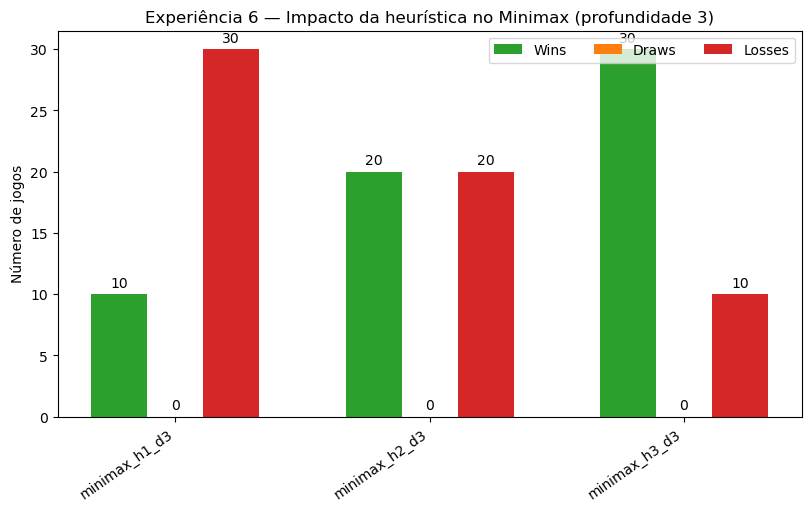

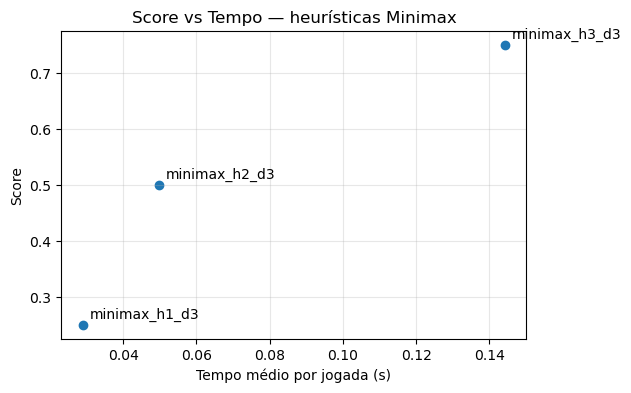

In [ ]:
plot_bars(stats_minimax_h, "Impacto da heurística no Minimax (profundidade 3)")
plot_score_vs_time(stats_minimax_h, "Score vs Tempo — heurísticas Minimax")

#### Discussão dos resultados

Os dados empíricos demonstram uma correlação direta e linear entre a complexidade da função de avaliação folha e a taxa de sucesso do agente. A adição de cada nova camada lógica traduziu-se num salto expressivo de performance:

* **O peso do controlo posicional (`h1` vs `h2`):** A transição da heurística 1 (que apenas avaliava ameaças) para a heurística 2 (ameaças + controlo central) duplicou a taxa de vitórias (saltando de 10 para 20 vitórias). Isto prova estatisticamente a premissa teórica de que dominar o centro do tabuleiro no PopOut é uma vantagem tática fundamental. Além disso, o custo computacional desta verificação extra provou ser quase negligenciável.

* **A compensação do "Efeito de Horizonte" (`h2` vs `h3`):** A heurística 3 revelou-se a mais eficaz, conseguindo 30 vitórias (Score 0.75). Com um limite de profundidade de 3 níveis, o agente não tem visibilidade sobre jogadas que terminam o jogo no 4º passo. Ao incorporar a verificação de vitória no turno seguinte, a heurística 3 garante que o agente avalia e responde a ameaças críticas que ficam ligeiramente fora do limite de pesquisa padrão do algoritmo.

* **Custo vs Benefício:** O gráfico de dispersão evidencia que a inteligência artificial mais avançada (`minimax_h3_d3`) exige um aumento acentuado de tempo, saltando para cerca de 0.14s por jogada. No entanto, em termos práticos, 0.14 segundos continua a ser uma resposta instantânea à perceção humana. 

**Conclusão:** Para esta experiência, a profundidade de pesquisa foi fixada no nível 3 para garantir uma execução rápida e isolar o impacto das funções de avaliação. No entanto, dado o elevado fator de ramificação do PopOut, pesquisar em grandes profundidades (nível 5 ou superior) é inerentemente inviável para jogos em tempo real. Os resultados provam que a `heuristic3` é a solução ideal para este bloqueio computacional: a sua inteligência posicional e tática permite ao agente tomar decisões de alta qualidade mesmo operando sob estritas limitações de profundidade.

### Experiência 7 — Impacto da profundidade

O objetivo desta experiência é realizar um confronto direto entre as duas grandes abordagens implementadas neste projeto: o algoritmo determinístico Minimax (equipado com a sua função de avaliação mais avançada, a `heuristic3`) e o algoritmo probabilístico MCTS (configurado com o orçamento de referência de --- iterações).

Para compreender a escalabilidade e os limites práticos do Minimax face ao elevado fator de ramificação do PopOut (até 14 movimentos por turno), determinou-se a avaliação sob duas profundidades específicas:

* **Profundidade 3 (Baseline):** Estabelecida como o ponto de partida do algoritmo exaustivo. Garante um tempo de resposta computacional quase instantâneo, mas restringe a antecipação tática a apenas 3 turnos.
* **Profundidade 4 (Limiar Computacional):** Escolhida especificamente por representar o limite prático superior para a pesquisa exaustiva em tempo real. No pior cenário combinatório, o nível 4 exige a avaliação de aproximadamente 38.416 estados. Testar esta profundidade permite verificar se um nível adicional de previsão confere maturidade estratégica suficiente para competir com o MCTS, avaliando simultaneamente a penalização temporal imposta pelo crescimento exponencial da árvore.

Pretende-se, assim, analisar o *trade-off* entre a precisão matemática da procura exaustiva em profundidade controlada e a eficiência da procura seletiva por simulação estatística do MCTS.

In [6]:
# Referência MCTS para comparação
mcts_ref = MoveMCTS(max_iter=1000, expansion_policy=get_win_block_or_all)

minimax_depth_variants = [
    ("minimax_h3_d3", Minimax(max_depth=3, heuristic=heuristic3, pruning=True)),
    ("minimax_h3_d4", Minimax(max_depth=4, heuristic=heuristic3, pruning=True)),
    ("mcts_ref_1000", mcts_ref),
]

stats_depth = variants_stats(minimax_depth_variants, n_games=10)
stats_dataframe(stats_depth)

NameError: name 'variants_stats' is not defined

In [8]:
plot_bars(stats_depth, "Minimax: profundidade 3 vs 4 vs MCTS ref")
plot_score_vs_time(stats_depth, "Score vs Tempo — Minimax vs MCTS")

NameError: name 'plot_bars' is not defined

#### Discussão de resultados
............

---
## 5. MCTS híbrido — Minimax como avaliador do rollout

Uma extensão natural é **substituir o rollout aleatório** do MCTS por uma avaliação Minimax. Em vez de simular um jogo aleatório até ao fim, o nó expandido é avaliado com Minimax de profundidade limitada.

**Vantagem**: o avaliador é determinístico e usa conhecimento do domínio — cada "simulação" é mais informativa do que um rollout aleatório.

**Desvantagem**: cada avaliação é muito mais cara computacionalmente. Por isso, o número de iterações tem de ser reduzido para manter um tempo de resposta aceitável. Com 100 iterações e Minimax de profundidade 3, o custo total por jogada é comparável ao MCTS puro com 1000 iterações.

### Parâmetro `normalize_minimax`

- `normalize_minimax=True`: o resultado do Minimax (valor contínuo em `[-1, 1]`) é convertido para `{-1, 0, 1}` antes do backpropagation — compatível com a implementação standard.
- `normalize_minimax=False`: o valor contínuo é propagado directamente — o que muda a escala do UCT e pode melhorar a discriminação entre nós com scores parecidos, mas a interacção com o factor de exploração `c = √2` deixa de ser calibrada para o intervalo `[-1, 1]`.

### Experiência 8 — MCTS híbrido: normalize vs raw


In [10]:
minimax_eval = Minimax(max_depth=3, heuristic=heuristic3, pruning=True)

hybrid_variants = [
    ("hybrid_norm_100", MoveMCTS(
        max_iter=100,
        expansion_policy=get_win_block_or_all,
        use_minimax=True,
        minimax_agent=minimax_eval,
        normalize_minimax=True,
    )),
    ("hybrid_raw_100", MoveMCTS(
        max_iter=100,
        expansion_policy=get_win_block_or_all,
        use_minimax=True,
        minimax_agent=minimax_eval,
        normalize_minimax=False,
    )),
    ("mcts_pure_1000", MoveMCTS(max_iter=1000, expansion_policy=get_win_block_or_all)),
]

stats_hybrid = variants_stats(hybrid_variants, n_games=10)
stats_dataframe(stats_hybrid)

NameError: name 'variants_stats' is not defined

In [11]:
plot_bars(stats_hybrid, "MCTS híbrido vs MCTS puro")
plot_score_vs_time(stats_hybrid, "Score vs Tempo — híbrido")

NameError: name 'plot_bars' is not defined

#### Discussão de resultados
.........

---
## 6. Comparação final - todos os melhores agentes

Junta os melhores agentes de cada bloco numa competição única para determinar o agente final.

In [21]:
# Substituir pelos nomes reais após executar as experiências anteriores
# e identificar o vencedor de cada bloco

final_variants = [
    # Melhor do bloco 2 (MCTS base)
    ("mcts_win_tree_300",  MCTS(max_iter=300, heuristic_win=True, save_tree=True)),

    # Melhor do bloco 3 (MoveMCTS — ajustar política conforme Exp 5)
    ("move_win_block_1000", MoveMCTS(max_iter=1000, expansion_policy=get_win_block_or_all)),

    # Melhor do bloco 4 (Minimax — ajustar profundidade conforme Exp 7)
    ("minimax_h3_d3",      Minimax(max_depth=3, heuristic=heuristic3, pruning=True)),
    ("minimax_h3_d4",      Minimax(max_depth=4, heuristic=heuristic3, pruning=True)),

    # Melhor do bloco 5 (híbrido)
    ("hybrid_norm_100",    MoveMCTS(
        max_iter=100,
        expansion_policy=get_win_block_or_all,
        use_minimax=True,
        minimax_agent=Minimax(max_depth=3, heuristic=heuristic3, pruning=True),
        normalize_minimax=True,
    )),
]

stats_final = variants_stats(final_variants, n_games=15)
stats_dataframe(stats_final)

,wins,draws,losses,total_games,win_rate,draw_rate,loss_rate,score,avg_time_per_move
move_win_block_1000,99,0,21,120,0.825000,0.000000,0.175000,0.825000,3.712127
mcts_win_tree_300,78,1,41,120,0.650000,0.008333,0.341667,0.654167,0.154184
minimax_h3_d4,69,0,51,120,0.575000,0.000000,0.425000,0.575000,0.832634
minimax_h3_d3,42,0,78,120,0.350000,0.000000,0.650000,0.350000,1.070632
hybrid_norm_100,11,1,108,120,0.091667,0.008333,0.900000,0.095833,2.215649


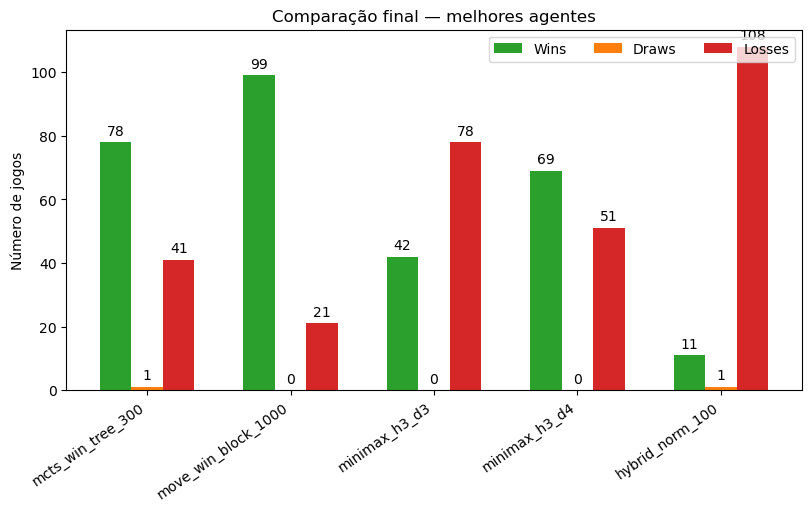

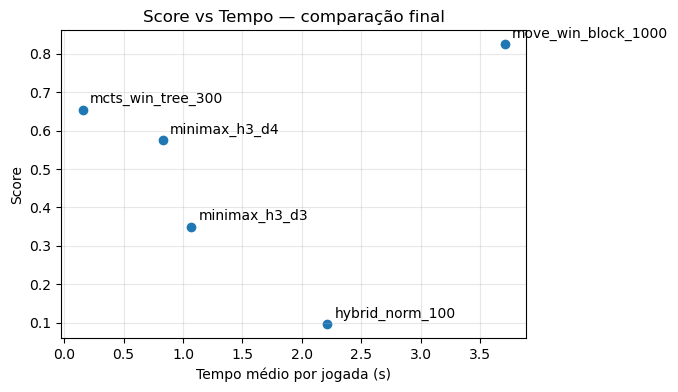

In [22]:
plot_bars(stats_final, "Comparação final — melhores agentes")
plot_score_vs_time(stats_final, "Score vs Tempo — comparação final")

#### Discussão — Comparação final

.........

---
## 7. Limitações e conclusão

### Limitações

- **Aleatoriedade**: o MCTS é estocástico. Diferentes execuções podem produzir resultados diferentes, especialmente com amostras pequenas. Os resultados devem ser interpretados como tendências, não como prova estatística forte.
- **Tamanho das amostras**: o número de jogos por par é limitado pelo tempo de execução. Amostras de 10-20 jogos têm variância elevada — diferenças de score inferiores a 0.05 são pouco fiáveis.
- **Custo do `block`**: a heurística `block` e a política `get_win_block_or_all` aumentam muito o custo por iteração porque avaliam as respostas do adversário. O impacto no tempo deve sempre ser considerado.
- **Heurísticas do Minimax**: as heurísticas implementadas são baseadas em conhecimento geral do Connect-4. Heurísticas específicas para PopOut (que consideram o efeito dos pops) poderiam melhorar o Minimax de forma significativa.
- **Factor de ramificação**: o PopOut tem até 14 movimentos por turno, o que limita severamente a profundidade prática do Minimax. O alpha-beta pruning ajuda, mas a qualidade da ordenação dos nós afecta muito a eficácia da poda — e nesta implementação os nós não são ordenados por valor estimado antes de explorar.

### Conclusão

........

**Agente final escolhido**:  
**Justificação**: 